# 11.07日学习整理
## 1.exercise
### 1.1ndarray
1.1.1 用其他形状(例如三维张量)替换广播机制中按元素操作的两个张量，结果是否与预期相同？


In [1]:
import torch
#把两个例子张量写出来
a = torch.arange(36)
a = a.reshape(3,4,3)
# 张量a是3行4列2张表，维度是3
b = torch.tensor([[2,1,4,3],[1,2,3,4]])
# 张量b是2行4列1张表，维度是2
print(a)
print(b)
print(a+b)

tensor([[[ 0,  1,  2],
         [ 3,  4,  5],
         [ 6,  7,  8],
         [ 9, 10, 11]],

        [[12, 13, 14],
         [15, 16, 17],
         [18, 19, 20],
         [21, 22, 23]],

        [[24, 25, 26],
         [27, 28, 29],
         [30, 31, 32],
         [33, 34, 35]]])
tensor([[2, 1, 4, 3],
        [1, 2, 3, 4]])


RuntimeError: The size of tensor a (3) must match the size of tensor b (4) at non-singleton dimension 2

oo，这里报错了，标记一下：
RuntimeError: The size of tensor a (3) must match the size of tensor b (4) at non-singleton dimension 2
在第三个非1的维度上，张量a的尺寸必须和张量b的尺寸配对

In [4]:
import torch
#把两个例子张量写出来
a = torch.arange(36)
a = a.reshape(3,3,4)
# 张量a是3张表3行4列，维度是3,a.shape=(3,3,4)
b = torch.tensor([[2,1,4,3],[1,2,3,4],[2,2,2,2]])
# 张量b是一张表3行4列，维度是2,b.shape=(1,3,4)
print(a)
print(b)
print(a+b)

tensor([[[ 0,  1,  2,  3],
         [ 4,  5,  6,  7],
         [ 8,  9, 10, 11]],

        [[12, 13, 14, 15],
         [16, 17, 18, 19],
         [20, 21, 22, 23]],

        [[24, 25, 26, 27],
         [28, 29, 30, 31],
         [32, 33, 34, 35]]])
tensor([[2, 1, 4, 3],
        [1, 2, 3, 4],
        [2, 2, 2, 2]])
tensor([[[ 2,  2,  6,  6],
         [ 5,  7,  9, 11],
         [10, 11, 12, 13]],

        [[14, 14, 18, 18],
         [17, 19, 21, 23],
         [22, 23, 24, 25]],

        [[26, 26, 30, 30],
         [29, 31, 33, 35],
         [34, 35, 36, 37]]])


### 1.2 pandas
1.2.1 创建包含更多行和列的原始数据集
(1):删除缺失值最多的列
(2):将预处理后的数据集转换为张量格式

In [11]:
#1.把这个数据集写出来
import pandas as pd
import torch

# 创建原始数据集
data = pd.DataFrame({
    'feature_1': [1, 2, 3, 4, 5, 6],
    'feature_2': [10, 20, 30, 40, 50, 60],
    'feature_3': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6],
    'feature_4': [None, None, 0.9, None, None, 1.2]
})

display(data)
#统计每一列的缺失值
NaN_counts = data.isna().sum()
print(NaN_counts)
column_to_drop =NaN_counts.idxmax()
data = data.drop(columns=[column_to_drop])
display(data)
#转化成张量
x = torch.tensor(data.to_numpy(), dtype=torch.float32)
print(x)
print(x.shape)
print(x.dtype)

,feature_1,feature_2,feature_3,feature_4
0,1,10,0.1,NaN
1,2,20,0.2,NaN
2,3,30,0.3,0.9
3,4,40,0.4,NaN
4,5,50,0.5,NaN
5,6,60,0.6,1.2


feature_1    0
feature_2    0
feature_3    0
feature_4    4
dtype: int64


,feature_1,feature_2,feature_3
0,1,10,0.1
1,2,20,0.2
2,3,30,0.3
3,4,40,0.4
4,5,50,0.5
5,6,60,0.6


tensor([[ 1.0000, 10.0000,  0.1000],
        [ 2.0000, 20.0000,  0.2000],
        [ 3.0000, 30.0000,  0.3000],
        [ 4.0000, 40.0000,  0.4000],
        [ 5.0000, 50.0000,  0.5000],
        [ 6.0000, 60.0000,  0.6000]])
torch.Size([6, 3])
torch.float32


# 1.3 linear-algebra
1.3.1 本节中定义了形状(2,3,4)的张量X。len(X)的输出结果是什么？
1.3.2 运行A/A.sum(axis=1),看看会发生什么，请分析一下原因？
1.3.3 考虑一个具有形状(2,3,4)的张量，在轴0、1、2上的求和输出是什么形状？
1.3.4 为linalg.norm函数提供三个或者更多轴的张量，并观察其输出。对于任意形状的张量为这个函数计算得到什么？

In [16]:
#1.3.1 len()
X = torch.zeros(2,3,4)
print(X)
print("len(X)的输出结果是", len(X) )
#1.3.2 运行A/A.sum(axis=1)
A = torch.tensor([[[1,2,3,4],[2,3,4,5],[3,4,5,6]],
[[5,6,7,8],[7,8,9,10],[10,11,12,13]]])
print("A是", A)
print("A.sum(axis=1)是",A.sum(axis=1))
# 这里A.shape=(2,3,4),而A.sum(axis=1).shape=(2,4)，
# 不保留维数的话是无法做除法的(keepdim=True)
print("结果是", A/A.sum(axis=1,keepdim=True))
#1.3.3 不同轴上的求和
print(A.shape)
print("axis=0:",A.sum(axis=0))
print("axis=1:",A.sum(axis=1))
print("axis=2:",A.sum(axis=2))
#1.3.4 linalg.norm
#这里直接对A做会有问题，因为linalg.norm函数需要输入浮点型或者是复数类型
B = torch.tensor([
    [[1, 2, 3, 4], [2, 3, 4, 5], [3, 4, 5, 6]],
    [[5, 6, 7, 8], [7, 8, 9, 10], [10, 11, 12, 13]]
], dtype=torch.float32)
Y = torch.linalg.norm(B)
print(Y)


tensor([[[0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.]],

        [[0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.]]])
len(X)的输出结果是 2
A是 tensor([[[ 1,  2,  3,  4],
         [ 2,  3,  4,  5],
         [ 3,  4,  5,  6]],

        [[ 5,  6,  7,  8],
         [ 7,  8,  9, 10],
         [10, 11, 12, 13]]])
A.sum(axis=1)是 tensor([[ 6,  9, 12, 15],
        [22, 25, 28, 31]])
结果是 tensor([[[0.1667, 0.2222, 0.2500, 0.2667],
         [0.3333, 0.3333, 0.3333, 0.3333],
         [0.5000, 0.4444, 0.4167, 0.4000]],

        [[0.2273, 0.2400, 0.2500, 0.2581],
         [0.3182, 0.3200, 0.3214, 0.3226],
         [0.4545, 0.4400, 0.4286, 0.4194]]])
torch.Size([2, 3, 4])
axis=0: tensor([[ 6,  8, 10, 12],
        [ 9, 11, 13, 15],
        [13, 15, 17, 19]])
axis=1: tensor([[ 6,  9, 12, 15],
        [22, 25, 28, 31]])
axis=2: tensor([[10, 14, 18],
        [26, 34, 46]])
tensor(34.2345)


 对于一般的张量$(x)_{i_1,i_2,...,i_n}\in \mathbb{R}^{prod_{j=i}^{n}i_j}$,我们计算linalg.norm()其实就是把每个元素平方后求和再开根号，相当于Frobenius范数一个自然的推广

### 1.4 calculus
1.绘制函数y=f(x)=x^{3}-\frac{1}{x}的梯度

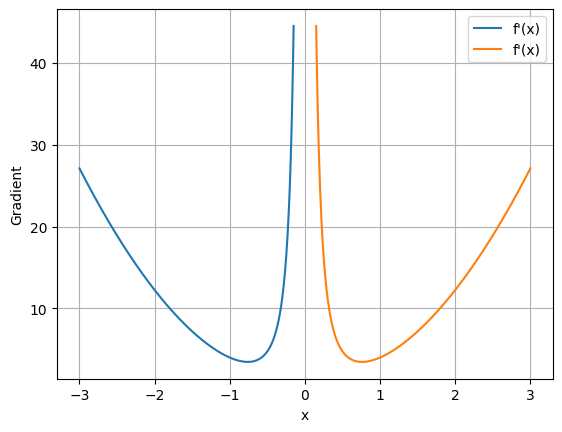

In [ ]:
#1.4.1 绘制函数
import numpy as np
import matplotlib.pyplot as plt
x1 = np.linspace(-3, -0.15, 500)
x2 = np.linspace(0.15, 3, 500)
def grad_f(x):
    return 3*x**2 + 1/x**2
plt.plot(x1,grad_f(x1), label="f'(x)")
plt.plot(x2,grad_f(x2), label="f'(x)")

plt.xlabel("x")
plt.ylabel("Gradient")
plt.legend()
plt.grid()
plt.show()


### 1.6 autograd
1.在运行反向传播函数之后，立即再次运行它，看看会发生什么。
2.在控制流的例子中，我们计算d关于a的导数，如果将变量更改为随机向量或者矩阵，会发生什么？

In [ ]:
#1.6.1 再次运行反向传播函数
import torch
x = torch.arange(4.0)
print(x)
x.requires_grad_(True)
x.grad
y = 2 * torch.dot(x,x)
print(y)
y.backward()
y.backward()
print(x.grad)


tensor([0., 1., 2., 3.])
tensor(28., grad_fn=<MulBackward0>)


RuntimeError: Trying to backward through the graph a second time (or directly access saved tensors after they have already been freed). Saved intermediate values of the graph are freed when you call .backward() or autograd.grad(). Specify retain_graph=True if you need to backward through the graph a second time or if you need to access saved tensors after calling backward.

这里报错了！
1.第一次反向传播时python沿着计算图返回了x的梯度，然后嘞给计算图释放了，那么第二次反向传播就没有计算图了
2.如果第一次反向传播写成y.backward(retain_graph=True),那么计算图就不会被释放而被保留，那么第二次反向传播得到的梯度相当于2倍第一次返回的梯度
3.所以实际训练的时候需要使用x.grad.zero_()来清空梯度

In [ ]:
#1.4.2 将a变成随机向量或者矩阵
## 1.我们先把a变成矩阵看看
a = torch.tensor([1.0, 2.0],requires_grad=True)
d = (a**2).sum()
d.backward()
print(a.grad)
## 2.如果d输出的是向量，那么梯度是jacobian矩阵

tensor([2., 4.])


### 1.7 probability
1. 假设我们是一系列随机变量，例如A，B，C，其中B只依赖A，C只依赖B，可以简化联合概率P(A,B,C)吗？
answer:
P(A,B,C)=P(A)P(B|A)P(C|AB)
        =P(A)P(B|A)P(C|B)
2. 在:numref:subsec_probability_hiv_app中，第一个测试更准确。为什么不运行第一个测试两次，而是同时运行第一个和第二个测试？
answer:
我们实际上假设了：测试结果在是否感染的条件下是独立的
如果两个测试的误差缺失条件成立，那么两次测试确实提供独立的新信息